In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

url = r"C:\My-Drive\Learning\repositories\ai-learning\AI-Naresh-IT\EDA_LLM\titanic_ dataset_final.csv"
df = pd.read_csv(url)
df

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S
...,...,...,...,...,...,...,...,...,...,...,...,...
886,887,0,2,"Montvila, Rev. Juozas",male,27.0,0,0,211536,13.0000,NaN,S
887,888,1,1,"Graham, Miss. Margaret Edith",female,19.0,0,0,112053,30.0000,B42,S
888,889,0,3,"Johnston, Miss. Catherine Helen ""Carrie""",female,NaN,1,2,W./C. 6607,23.4500,NaN,S
889,890,1,1,"Behr, Mr. Karl Howell",male,26.0,0,0,111369,30.0000,C148,C


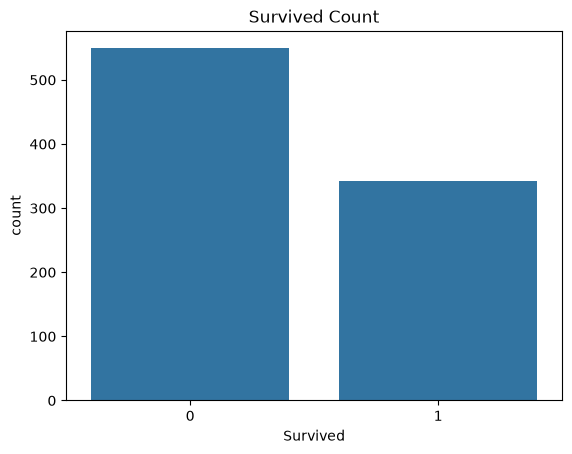

In [5]:
sns.countplot(x='Survived', data=df)
plt.title('Survived Count')
plt.show()

In [8]:
import ollama

def generate_insights(df_summary):
    prompt = f"Analyze the dataset summary and provide insights:\n{df_summary}"
    response = ollama.chat(model="gemma3:270m", messages=[{"role": "user", "content": prompt}])
    return response['message']["content"]

# Generate AI Insights
summary = df.describe().to_string()
insights = generate_insights(summary)
print("\n 🔥 AI-Generated Insights:\n", insights)


 🔥 AI-Generated Insights:
 Here's an analysis of the provided dataset summary, highlighting key insights:

**Overall Sentiment:**

The dataset shows a mixed sentiment towards the passenger ID, with a relatively positive sentiment for the passengers with `Survived` and `Pclass`.  The overall sentiment is positive, indicating a positive impression of the passenger population.  The `Age` and `SibSp` values indicate a positive sentiment towards the passenger age and number of passengers, respectively.

**Passenger ID:**

*   **Number of Passengers:** 891
*   **Passenger ID:** 891.000000
*   **Passenger ID:** 891.000000
*   **Passenger ID:** 891.000000
*   **Passenger ID:** 891.000000

**Mean Passenger ID:**

*   **Mean Passenger ID:** 446.000000
*   **Mean Passenger ID:** 0.383838
*   **Mean Passenger ID:** 29.699118
*   **Mean Passenger ID:** 0.523008
*   **Mean Passenger ID:** 0.381594

**Standard Deviation:**

*   **Standard Deviation:** 257.353842
*   **Standard Deviation:** 14.526497

In [9]:
import gradio as gr

def eda_analysis(file):
    df = pd.read_csv(file.name)
    summary = df.describe().to_string()
    insights = generate_insights(summary)
    return insights
# Create a web interface for AI-powered EDA
demo = gr.Interface(
    fn=eda_analysis,
    inputs=gr.File(label="Upload CSV"),
    outputs=gr.Textbox(label="AI-Generated Insights"),
    title="AI-Powered EDA with Gradio"
)

# Launch the Gradio demo for AI-powered EDA
demo.launch()

c:\My-Drive\Learning\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


* Running on local URL:  http://127.0.0.1:7860
* To create a public link, set `share=True` in `launch()`.
